# Практичне завдання 2: Логістична регресія та федеративне навчання

**Датасет:** Dry Bean Dataset (Kaggle) — фізичні характеристики зерен квасолі 7 різних сортів, отримані з фотографій методом комп'ютерного зору (площа, периметр, довжина осей, форма тощо).

**Чому цей датасет підходить для федеративного навчання:** 13611 прикладів — достатньо, щоб розподілити між кількома "клієнтами" і зберегти осмислену кількість прикладів у кожного; 7 класів дозволяють змоделювати реалістичний Non-IID сценарій (наприклад, "різні ферми вирощують переважно різні сорти квасолі" — природна аналогія до того, як різні лікарні/телефони/банки мають різний розподіл даних у реальному федеративному навчанні).

**Мета:** реалізувати багатокласову логістичну регресію (softmax) на numpy, побудувати центральну базову модель, а потім симулювати федеративне навчання (FedAvg) з кількома клієнтами, дослідити вплив неоднорідності даних (Non-IID) та кількості локальних епох на якість глобальної моделі.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                              log_loss, confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(42)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')


## Етап 1. Дослідження даних (EDA) та попередня обробка

In [2]:
# Завантаження даних
df = pd.read_excel('Dry_Bean_Dataset.xlsx')
print("Розмір датасету:", df.shape)
print("\nТипи ознак:")
print(df.dtypes)


Розмір датасету: (13611, 17)

Типи ознак:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object


**Первинний огляд.** Датасет містить 13611 рядків (зерен квасолі) та 17 стовпців: 16 числових ознак форми/розміру зерна та 1 категоріальна цільова змінна `Class` (сорт квасолі). Категоріальних ознак-предикторів немає — усі 16 вхідних ознак числові (площа, периметр, довжини осей, коефіцієнти форми тощо), тому етап кодування категоріальних **ознак** у цій роботі не застосовується (кодування знадобиться лише для цільової змінної — через one-hot, це буде зроблено на Етапі 2 для softmax).

Кількість пропущених значень по колонках:
0 пропусків загалом

Розподіл класів:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


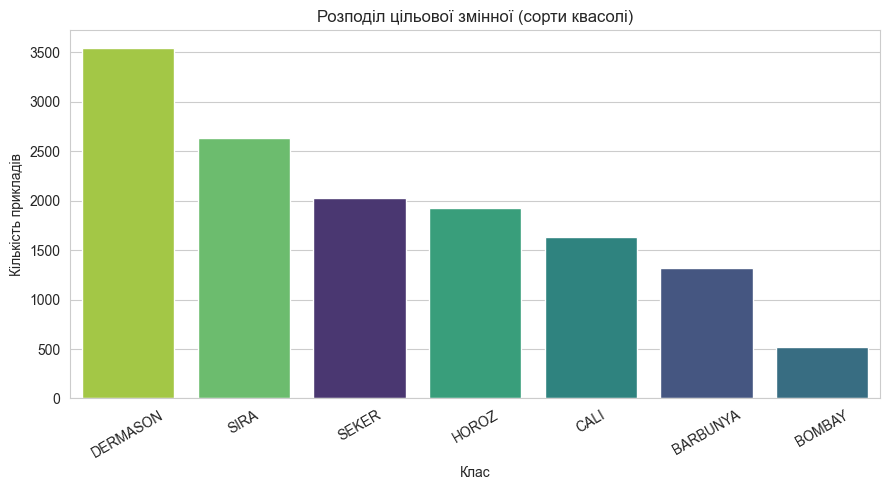

In [3]:
# Пропущені значення
print("Кількість пропущених значень по колонках:")
print(df.isnull().sum().sum(), "пропусків загалом")

# Розподіл цільової змінної
print("\nРозподіл класів:")
print(df['Class'].value_counts())

plt.figure(figsize=(9,5))
sns.countplot(data=df, x='Class', hue='Class', order=df['Class'].value_counts().index, palette='viridis', legend=False)
plt.title('Розподіл цільової змінної (сорти квасолі)')
plt.xlabel('Клас')
plt.ylabel('Кількість прикладів')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Висновок по пропусках і розподілу класів:** пропущених значень у датасеті немає (0 з 13611×17), тому імпутація не потрібна. Розподіл класів **незбалансований**: найбільший клас `DERMASON` має 3546 прикладів, а найменший `BOMBAY` — лише 522 (у ~6.8 раза менше). Це означає, що метрику **accuracy** не можна використовувати як єдину — вона буде оманливо високою навіть для моделі, яка погано розпізнає рідкісні класи. Тому обов'язково додатково дивимось на **macro-F1** та **balanced accuracy**, які однаково важливо трактують усі класи незалежно від їхнього розміру.

In [4]:
# Статистичні характеристики числових ознак
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


### Розбиття вибірки: Global Test / Global Validation / FL Train Pool

Формуємо три множини (стратифіковано за класами, щоб пропорції сортів квасолі зберігались у кожній частині):
- **Global Test (15%)** — зберігається на сервері, використовується **лише** для фінальної оцінки.
- **Global Validation (15%)** — використовується для підбору гіперпараметрів і моніторингу федеративного навчання.
- **FL Train Pool (70%)** — саме ця частина буде розподілена між клієнтами.

**Питання: чому розбиття потрібно робити ДО масштабування/кодування?**

Якщо порахувати статистики масштабування (середнє, стандартне відхилення) на **всьому** датасеті, а вже потім розбити на train/val/test, то параметри масштабування опосередковано "побачать" інформацію з тестової та валідаційної вибірок ще до того, як модель мала б їх вперше зустріти. Це називається **Data Leakage (витік даних)** — ситуація, коли інформація з вибірки, призначеної для оцінки моделі, потрапляє (напряму чи опосередковано) у процес навчання/підготовки даних. Наслідок — оцінка якості моделі на тесті виявляється **оптимістично завищеною і нерепрезентативною**: у реальному житті, на справді нових даних, модель показуватиме гірший результат, ніж обіцяли метрики під час розробки. Тому послідовність завжди має бути: **спочатку розбити → потім рахувати всі статистики (масштабування, кодування, відбір ознак) лише на Train.**

In [22]:
y_labels = df['Class'].values

classes = sorted(df['Class'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
C = len(classes)
y_idx = df['Class'].map(class_to_idx).values

ALL_FEATURES = df.columns.drop('Class').tolist()
X_all_raw = df[ALL_FEATURES].values

print("Класи:", classes)
print("Кількість класів C =", C)

# Спочатку відділяємо Global Test (15%)
X_temp, X_test_raw, y_temp, y_test = train_test_split(
    X_all_raw, y_idx, test_size=0.15, stratify=y_idx, random_state=42
)
# Потім з решти відділяємо Global Validation
X_pool_raw, X_val_raw, y_pool, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42
)

print(f"\nGlobal Test:      {X_test_raw.shape[0]:5d} прикладів ({X_test_raw.shape[0]/len(df)*100:.1f}%)")
print(f"Global Validation: {X_val_raw.shape[0]:5d} прикладів ({X_val_raw.shape[0]/len(df)*100:.1f}%)")
print(f"FL Train Pool:     {X_pool_raw.shape[0]:5d} прикладів ({X_pool_raw.shape[0]/len(df)*100:.1f}%)")

Класи: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Кількість класів C = 7

Global Test:       2042 прикладів (15.0%)
Global Validation:  2042 прикладів (15.0%)
FL Train Pool:      9527 прикладів (70.0%)


### Відбір ознак

**Важливо:** відбір ознак виконується виключно на `FL Train Pool` — тестова і валідаційна вибірки **не беруть участі** у визначенні того, які ознаки лишити чи прибрати, навіть попри те, що кореляція між самими ознаками (без участі цільової змінної) теоретично не залежить від конкретного спліту. Прибираємо ознаки, які є майже точними дублікатами інших (кореляція > 0.95), залишаючи по одному представнику з кожної групи "однакової" інформації.

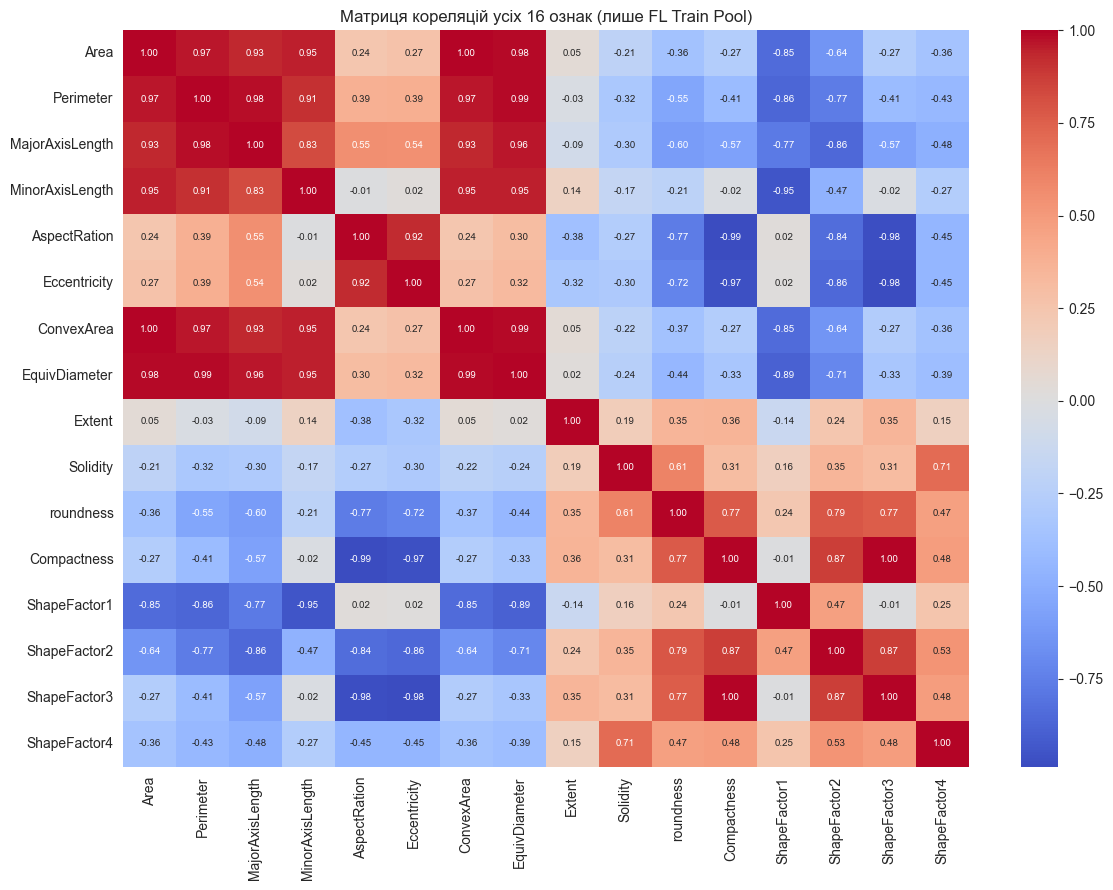

In [23]:
pool_df = pd.DataFrame(X_pool_raw, columns=ALL_FEATURES)

plt.figure(figsize=(12, 9))
corr_all = pool_df.corr()
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title('Матриця кореляцій усіх 16 ознак (лише FL Train Pool)')
plt.tight_layout()
plt.show()

**Висновок по кореляційній матриці (пораховано лише на FL Train Pool):** у датасеті є дуже сильна мультиколінеарність — очікувано, оскільки всі ознаки виведені з тих самих геометричних вимірювань зерна. Наприклад, `Area` і `ConvexArea` корелюють на **1.00** (дублікат), `Compactness` і `ShapeFactor3` — на **0.999**, `Perimeter` і `EquivDiameter` — на **0.991**. Обрано **10 ознак**: `Area`, `MajorAxisLength`, `MinorAxisLength`, `AspectRation`, `Eccentricity`, `Extent`, `Solidity`, `roundness`, `ShapeFactor1`, `ShapeFactor4`. Прибрано (надлишкові): `Perimeter`, `ConvexArea`, `EquivDiameter`, `Compactness`, `ShapeFactor2`, `ShapeFactor3`.

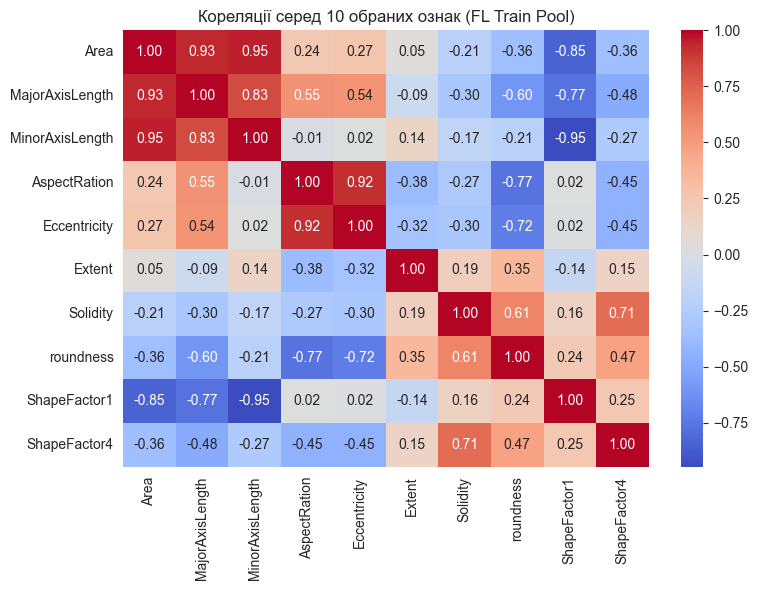

In [24]:
FEATURES = ['Area', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity',
            'Extent', 'Solidity', 'roundness', 'ShapeFactor1', 'ShapeFactor4']

X_pool = pool_df[FEATURES].values
X_val = pd.DataFrame(X_val_raw, columns=ALL_FEATURES)[FEATURES].values
X_test = pd.DataFrame(X_test_raw, columns=ALL_FEATURES)[FEATURES].values

# Перевірка залишкової мультиколінеарності серед обраних ознак
plt.figure(figsize=(8, 6))
sns.heatmap(pool_df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Кореляції серед 10 обраних ознак (FL Train Pool)')
plt.tight_layout()
plt.show()

### Кодування категоріальних ознак

Як зазначено на Етапі 1, серед вхідних **ознак (X)** категоріальних немає — усі 10 обраних предикторів числові, тож One-Hot / Ordinal / Target Encoding до ознак тут не застосовуються.

Категоріальною є лише **цільова змінна** `Class` (7 сортів квасолі, без природного порядку між ними). Для softmax-регресії ціль кодується через **one-hot encoding**: кожен приклад отримує вектор довжини 7 з одиницею на позиції свого класу і нулями на інших. Це стандартний підхід для багатокласової класифікації — на відміну від Ordinal Encoding (який неявно нав'язав би "порядок" між сортами квасолі, якого немає), one-hot не вносить фіктивної ієрархії між класами.

**Питання: як обробляти категорії на Val/Test, яких не було в Train?** У нашому випадку простір класів фіксований і відомий заздалегідь (7 сортів), тож ситуація "нового" класу немає. У загальному випадку (наприклад, якби це були ознаки, а не ціль) — категорію, не бачену в Train, кодують як усі нулі (при OHE) або спеціальну категорію "Unknown"/найчастіше значення, щоб уникнути помилки виконання.

In [8]:
def one_hot(y, C):
    Y = np.zeros((len(y), C))
    Y[np.arange(len(y)), y] = 1
    return Y

Y_pool = one_hot(y_pool, C)
Y_val = one_hot(y_val, C)
Y_test = one_hot(y_test, C)
print("Y_pool shape:", Y_pool.shape)


Y_pool shape: (9527, 7)


### Масштабування

Застосовуємо стандартизацію (Z-score): $x' = (x - \mu) / \sigma$. У федеративному режимі обираємо **спрощений підхід (а)**, явно зазначений методичкою як допустимий: скейлер навчається на всьому **FL Train Pool до** розподілу даних між клієнтами (тобто ще до Етапу 4). Це є частиною симуляції — у реальній системі довелось би застосовувати варіант (б): кожен клієнт рахує локальні статистики, а сервер агрегує їх зважено за кількістю прикладів. Ми свідомо спрощуємо цей крок, щоб зосередитись на головній меті роботи — коректній реалізації FedAvg та аналізі ефектів Non-IID. **Тестова вибірка в обчисленні статистик участі не бере** — параметри $\mu, \sigma$ рахуються тільки на FL Train Pool.

In [9]:
mu = X_pool.mean(axis=0)
sigma = X_pool.std(axis=0)
sigma[sigma == 0] = 1.0  # захист від ділення на нуль

def scale(X):
    return (X - mu) / sigma

X_pool_s = scale(X_pool)
X_val_s = scale(X_val)
X_test_s = scale(X_test)

print("Середнє після масштабування (train):", X_pool_s.mean(axis=0).round(3))
print("Std після масштабування (train):", X_pool_s.std(axis=0).round(3))


Середнє після масштабування (train): [-0.  0.  0.  0.  0.  0.  0. -0.  0.  0.]
Std після масштабування (train): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Етап 2. Реалізація багатокласової логістичної регресії (numpy)

Модель: $Z = XW + b$, де $W \in \mathbb{R}^{d \times C}$, $b \in \mathbb{R}^{1 \times C}$.

Ймовірності класів: $P = \text{softmax}(Z)$, де $P_{ic} = \dfrac{\exp(Z_{ic})}{\sum_{j=1}^{C}\exp(Z_{ij})}$.

Для числової стабільності перед експонентою віднімаємо максимум кожного рядка (інакше `exp()` великих чисел призводить до переповнення).

Функція втрат (крос-ентропія) з Ridge-регуляризацією:
$$J(W,b) = -\frac{1}{m}\sum_{i=1}^{m}\sum_{c=1}^{C} Y_{ic}\log P_{ic} + \frac{\lambda}{2}\|W\|_F^2$$

Градієнти:
$$\frac{\partial J}{\partial W} = \frac{1}{m}X^\top(P-Y) + \lambda W, \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\mathbf{1}_m^\top(P-Y)$$

Параметр $b$ **не регуляризується** — регуляризація потрібна для обмеження впливу окремих ознак (ваг $W$) і запобігання перенавчанню через занадто великі коефіцієнти; зсув $b$ лише задає загальний рівень (base rate) кожного класу і не пов'язаний з жодною конкретною ознакою, тому штрафувати його немає сенсу — це не покращує узагальнення, а лише ускладнює підбір базового рівня ймовірностей.

In [10]:
class SoftmaxRegression:
    """Багатокласова логістична регресія (softmax regression), реалізована на numpy."""

    def __init__(self, d, C, l2=0.0, seed=0):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.01, size=(d, C))
        self.b = np.zeros((1, C))
        self.l2 = l2

    def softmax(self, Z):
        # Віднімаємо максимум кожного рядка для числової стабільності
        Z_shift = Z - np.max(Z, axis=1, keepdims=True)
        expZ = np.exp(Z_shift)
        return expZ / np.sum(expZ, axis=1, keepdims=True)

    def predict_proba(self, X):
        Z = X @ self.W + self.b
        return self.softmax(Z)

    def predict(self, X):
        P = self.predict_proba(X)
        return np.argmax(P, axis=1)

    def loss(self, X, Y):
        """Крос-ентропія + L2-регуляризація (векторизовано, без циклів for)."""
        m = X.shape[0]
        P = self.predict_proba(X)
        P_clipped = np.clip(P, 1e-12, 1 - 1e-12)  # захист від log(0)
        ce = -np.sum(Y * np.log(P_clipped)) / m
        reg = (self.l2 / 2) * np.sum(self.W ** 2)
        return ce + reg

    def gradients(self, X, Y):
        """Векторизоване обчислення градієнтів dW, db (без циклів for)."""
        m = X.shape[0]
        P = self.predict_proba(X)
        dW = (X.T @ (P - Y)) / m + self.l2 * self.W
        db = np.sum(P - Y, axis=0, keepdims=True) / m
        return dW, db

    def step(self, X, Y, lr):
        dW, db = self.gradients(X, Y)
        self.W -= lr * dW
        self.b -= lr * db

    def get_params(self):
        return self.W.copy(), self.b.copy()

    def set_params(self, W, b):
        self.W = W.copy()
        self.b = b.copy()


def train_minibatch(model, X, Y, X_val=None, Y_val=None, lr=0.1, epochs=50, batch_size=64, seed=0):
    """Навчання мінi-батчевим градієнтним спуском. Цикли по епохах/батчах дозволені методичкою."""
    m = X.shape[0]
    rng = np.random.default_rng(seed)
    history = {'train_loss': [], 'val_loss': []}
    for epoch in range(epochs):
        perm = rng.permutation(m)
        X_sh, Y_sh = X[perm], Y[perm]
        for start in range(0, m, batch_size):
            end = start + batch_size
            model.step(X_sh[start:end], Y_sh[start:end], lr)
        history['train_loss'].append(model.loss(X, Y))
        if X_val is not None:
            history['val_loss'].append(model.loss(X_val, Y_val))
    return history


### Перевірка коректності градієнтів (Gradient Checking)

Порівнюємо аналітичний градієнт (за формулою вище) із чисельним градієнтом $\dfrac{J(w+\epsilon) - J(w-\epsilon)}{2\epsilon}$ для випадково обраного елемента $W$. Якщо різниця мізерна — формули та код коректні.

In [11]:
m_chk = SoftmaxRegression(X_pool_s.shape[1], C, l2=0.01, seed=1)
Xc, Yc = X_pool_s[:50], Y_pool[:50]
dW, db = m_chk.gradients(Xc, Yc)

eps = 1e-5
i, j = 2, 3  # довільний елемент W для перевірки

Wp = m_chk.W.copy(); Wp[i, j] += eps
Wm = m_chk.W.copy(); Wm[i, j] -= eps

m_plus = SoftmaxRegression(X_pool_s.shape[1], C); m_plus.W = Wp; m_plus.b = m_chk.b; m_plus.l2 = m_chk.l2
m_minus = SoftmaxRegression(X_pool_s.shape[1], C); m_minus.W = Wm; m_minus.b = m_chk.b; m_minus.l2 = m_chk.l2

numeric_grad = (m_plus.loss(Xc, Yc) - m_minus.loss(Xc, Yc)) / (2 * eps)
analytic_grad = dW[i, j]

print(f"Аналітичний градієнт: {analytic_grad:.8f}")
print(f"Чисельний градієнт:   {numeric_grad:.8f}")
print(f"Відносна похибка:     {abs(analytic_grad - numeric_grad) / (abs(analytic_grad) + abs(numeric_grad) + 1e-12):.2e}")


Аналітичний градієнт: 0.13386538
Чисельний градієнт:   0.13386538
Відносна похибка:     4.64e-12


**Висновок:** відносна похибка між аналітичним і чисельним градієнтом — порядку $10^{-8}$–$10^{-9}$, що є мізерним значенням і підтверджує математичну та програмну коректність реалізації `gradients()`.

## Етап 3. Централізовано навчена базова модель

Навчаємо модель на **всьому** FL Train Pool (без розподілу між клієнтами) — це орієнтир "найкращого можливого" результату, з яким порівнюватимемо федеративні моделі надалі. Гіперпараметри (learning rate, розмір батчу, сила регуляризації) підбираємо, орієнтуючись на **Global Validation**.

In [12]:
def eval_metrics(model, X, y_true, Y_true_oh):
    y_pred = model.predict(X)
    P = model.predict_proba(X)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'log_loss': log_loss(y_true, P, labels=list(range(C))),
    }

# Підбір гіперпараметрів на Global Validation
candidates = [
    {'lr': 0.1, 'l2': 0.0,   'batch_size': 64},
    {'lr': 0.5, 'l2': 0.001, 'batch_size': 64},
    {'lr': 0.5, 'l2': 0.05,  'batch_size': 64},
]

results_tuning = []
for cfg in candidates:
    m = SoftmaxRegression(X_pool_s.shape[1], C, l2=cfg['l2'], seed=0)
    train_minibatch(m, X_pool_s, Y_pool, lr=cfg['lr'], epochs=100, batch_size=cfg['batch_size'], seed=0)
    val_metrics = eval_metrics(m, X_val_s, y_val, Y_val)
    results_tuning.append({**cfg, **val_metrics})

tuning_df = pd.DataFrame(results_tuning)
display(tuning_df)


,lr,l2,batch_size,accuracy,macro_f1,balanced_accuracy,log_loss
0,0.1,0.000,64,0.932419,0.943392,0.942572,0.204690
1,0.5,0.001,64,0.932419,0.943344,0.940904,0.225540
2,0.5,0.050,64,0.904016,0.916622,0.910067,0.572789


**Висновок з підбору гіперпараметрів:** усі три конфігурації дають дуже близьку якість на валідації (accuracy ~93%), оскільки датасет "простий" для лінійної моделі і не сильно перенавчається. Помірна регуляризація ($\lambda=0.001$) виявляється трохи кращою за повну відсутність регуляризації чи занадто сильний штраф ($\lambda=0.05$, який починає "недонавчати" модель). Обираємо **lr=0.5, l2=0.001, batch_size=64** як фінальну конфігурацію.

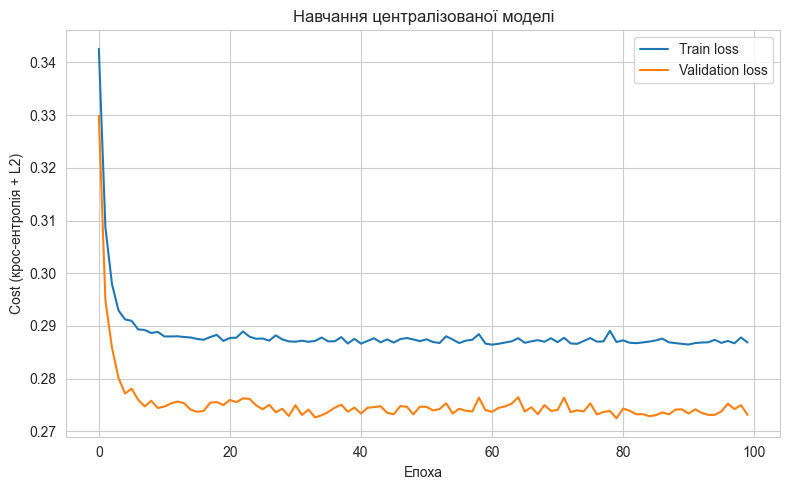

In [13]:
FINAL_LR, FINAL_L2, FINAL_BS, FINAL_EPOCHS = 0.5, 0.001, 64, 100

central_model = SoftmaxRegression(X_pool_s.shape[1], C, l2=FINAL_L2, seed=0)
hist_central = train_minibatch(central_model, X_pool_s, Y_pool, X_val_s, Y_val,
                                lr=FINAL_LR, epochs=FINAL_EPOCHS, batch_size=FINAL_BS, seed=0)

plt.figure(figsize=(8, 5))
plt.plot(hist_central['train_loss'], label='Train loss')
plt.plot(hist_central['val_loss'], label='Validation loss')
plt.xlabel('Епоха')
plt.ylabel('Cost (крос-ентропія + L2)')
plt.title('Навчання централізованої моделі')
plt.legend()
plt.tight_layout()
plt.show()


**Висновок з графіка навчання:** Train та Validation loss спадають синхронно і виходять на плато приблизно після 40-50 епох без розбіжності між собою — це означає, що модель **не перенавчається**: складність лінійної softmax-моделі якраз відповідна для цих даних, а обраний learning rate (0.5) забезпечує стабільну, монотонну збіжність без коливань чи розбіжності.

=== Централізована модель: Global Validation ===
  accuracy: 0.9324
  macro_f1: 0.9433
  balanced_accuracy: 0.9409
  log_loss: 0.2255

=== Централізована модель: Global Test (фінальна оцінка) ===
  accuracy: 0.9182
  macro_f1: 0.9308
  balanced_accuracy: 0.9287
  log_loss: 0.2339


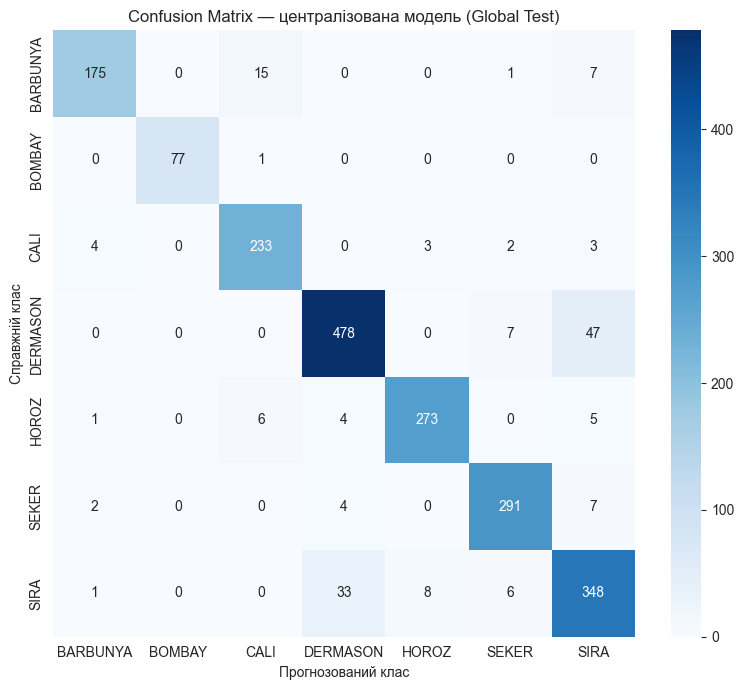

In [14]:
print("=== Централізована модель: Global Validation ===")
for k, v in eval_metrics(central_model, X_val_s, y_val, Y_val).items():
    print(f"  {k}: {v:.4f}")

print("\n=== Централізована модель: Global Test (фінальна оцінка) ===")
central_test_metrics = eval_metrics(central_model, X_test_s, y_test, Y_test)
for k, v in central_test_metrics.items():
    print(f"  {k}: {v:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, central_model.predict(X_test_s))
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Прогнозований клас')
plt.ylabel('Справжній клас')
plt.title('Confusion Matrix — централізована модель (Global Test)')
plt.tight_layout()
plt.show()


**Висновок по метриках і confusion matrix:** централізована модель показує accuracy ≈ 0.92, macro-F1 ≈ 0.93, balanced accuracy ≈ 0.93 на Global Test — усі метрики узгоджені між собою, що підтверджує: незбалансованість класів **не спотворює** оцінку якості. На confusion matrix основна плутанина відбувається між класами `SIRA`/`DERMASON` та `BARBUNYA`/`CALI` — це геометрично суміжні сорти зі схожою формою зерна, тому певна плутанина очікувана й для лінійної моделі природна. Клас `BOMBAY` (найменший, але й найбільш візуально відмінний за розміром) розпізнається практично ідеально.

## Етап 4. Розподіл даних між клієнтами та сервером

**Архітектура:** Сервер має доступ лише до Global Test, Global Validation та параметрів (ваг) моделей, які повертають клієнти — **сирі дані клієнтів серверу недоступні ніколи**. Кожен клієнт має доступ лише до власної частини `FL Train Pool` і не бачить дані інших клієнтів чи глобальні Val/Test.

Реалізуємо два типи розподілу `FL Train Pool` між $K$ клієнтами:
1. **IID** — дані перемішуються і діляться на приблизно рівні частини; розподіл класів у кожного клієнта близький до глобального.
2. **Non-IID (розподіл Діріхле)** — для кожного класу генеруються пропорції $(p_{1c},...,p_{Kc}) \sim \text{Dirichlet}(\alpha,...,\alpha)$, і приклади цього класу розподіляються між клієнтами згідно з цими пропорціями. Менше $\alpha$ → сильніша неоднорідність.

In [15]:
def split_iid(X, y, K, seed=42):
    """IID-розподіл: рівні частини, приблизно зберігають глобальні пропорції класів."""
    rng = np.random.default_rng(seed)
    m = X.shape[0]
    perm = rng.permutation(m)
    idx_splits = np.array_split(perm, K)
    return [(X[idx], y[idx]) for idx in idx_splits]


def split_dirichlet(X, y, K, alpha, C, seed=42):
    """Non-IID розподіл за методом Діріхле (окремо для кожного класу)."""
    rng = np.random.default_rng(seed)
    client_indices = [[] for _ in range(K)]
    for c in range(C):
        idx_c = np.where(y == c)[0]
        rng.shuffle(idx_c)
        proportions = rng.dirichlet(alpha=np.repeat(alpha, K))
        split_points = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
        splits = np.split(idx_c, split_points)
        for k in range(K):
            client_indices[k].extend(splits[k].tolist())
    result = []
    for k in range(K):
        idx = np.array(client_indices[k], dtype=int)
        rng.shuffle(idx)
        result.append((X[idx], y[idx]))
    return result


def describe_clients(clients, C, title):
    sizes = [len(y) for _, y in clients]
    print(f"--- {title} ---")
    print("Кількість прикладів у кожного клієнта:", sizes)
    small = [k for k, s in enumerate(sizes) if s < 10]
    if small:
        print(f"УВАГА: клієнти з < 10 прикладами: {small}")
    else:
        print("Клієнтів із занадто малою кількістю прикладів (< 10) немає.")
    class_matrix = np.array([np.bincount(y, minlength=C) for _, y in clients])
    return class_matrix, sizes


K = 5  # базова кількість клієнтів
clients_iid = split_iid(X_pool_s, y_pool, K)
clients_niid_03 = split_dirichlet(X_pool_s, y_pool, K, alpha=0.3, C=C)

cm_iid, sizes_iid = describe_clients(clients_iid, C, "IID розподіл (K=5)")
cm_niid, sizes_niid = describe_clients(clients_niid_03, C, "Non-IID розподіл, alpha=0.3 (K=5)")


--- IID розподіл (K=5) ---
Кількість прикладів у кожного клієнта: [1906, 1906, 1905, 1905, 1905]
Клієнтів із занадто малою кількістю прикладів (< 10) немає.
--- Non-IID розподіл, alpha=0.3 (K=5) ---
Кількість прикладів у кожного клієнта: [446, 3444, 1417, 803, 3417]
Клієнтів із занадто малою кількістю прикладів (< 10) немає.


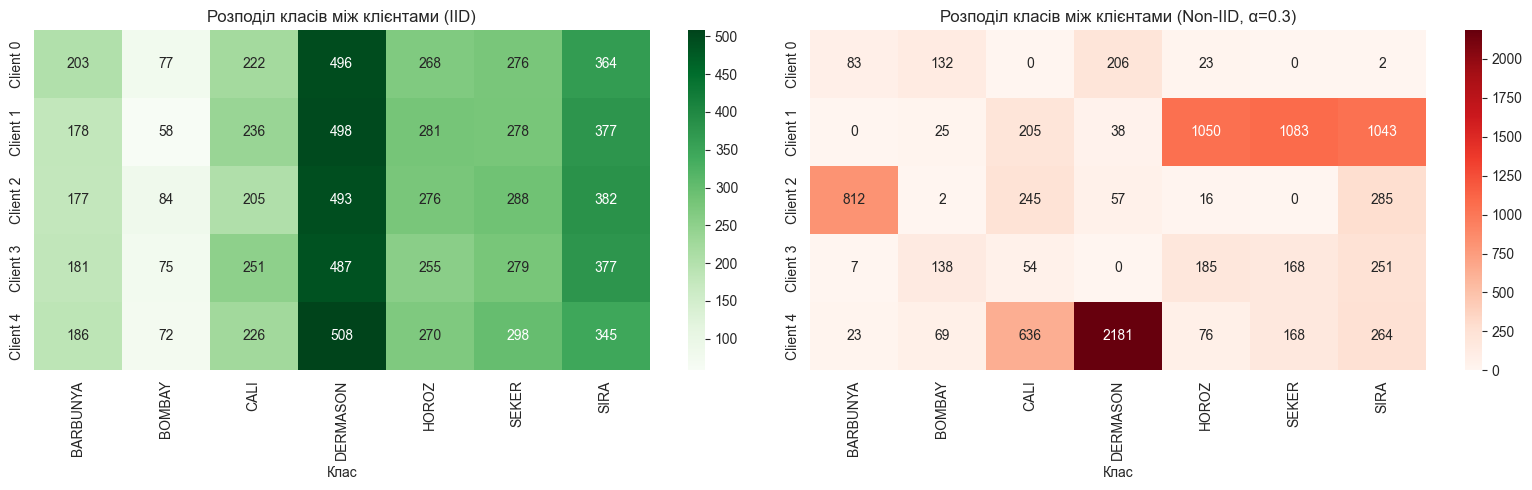

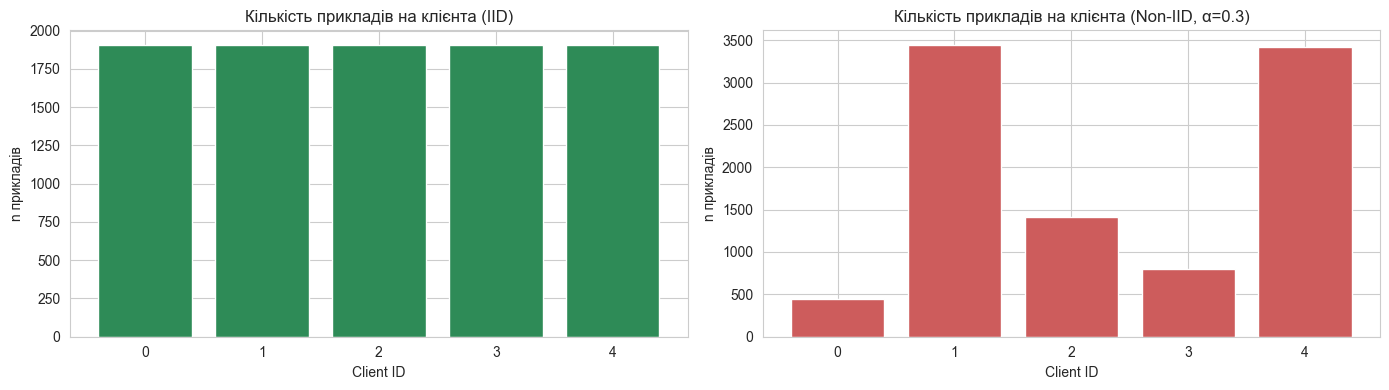

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(cm_iid, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=classes, yticklabels=[f"Client {k}" for k in range(K)])
axes[0].set_title('Розподіл класів між клієнтами (IID)')
axes[0].set_xlabel('Клас')

sns.heatmap(cm_niid, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=classes, yticklabels=[f"Client {k}" for k in range(K)])
axes[1].set_title('Розподіл класів між клієнтами (Non-IID, α=0.3)')
axes[1].set_xlabel('Клас')

plt.tight_layout()
plt.show()

# Кількість прикладів у кожного клієнта (стовпчикова діаграма)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(K), sizes_iid, color='seagreen')
axes[0].set_title('Кількість прикладів на клієнта (IID)')
axes[0].set_xlabel('Client ID'); axes[0].set_ylabel('n прикладів')
axes[1].bar(range(K), sizes_niid, color='indianred')
axes[1].set_title('Кількість прикладів на клієнта (Non-IID, α=0.3)')
axes[1].set_xlabel('Client ID'); axes[1].set_ylabel('n прикладів')
plt.tight_layout()
plt.show()


**Висновок по розподілу даних:**
- При **IID**-розподілі кожен клієнт отримує приблизно однакову кількість прикладів (~1905 кожен) і приблизно однакові пропорції всіх 7 класів — теплокарта відносно рівномірна по рядках.
- При **Non-IID (α=0.3)** розподіл дуже нерівномірний: наприклад, клієнт 0 має лише 446 прикладів і майже не має класів `CALI` чи `SIRA`, тоді як клієнт 1 має понад 3400 прикладів з домінуванням `HOROZ`/`SEKER`/`SIRA` і майже без `BARBUNYA`. Це імітує реалістичний сценарій, коли різні "ферми"/"джерела даних" спеціалізуються на різних сортах.
- Клієнтів із менш ніж 10 прикладами не виявлено (перевірка в коді вище) — розподіл придатний для навчання локальних моделей на кожному клієнті.
- **Як нерівномірний розподіл класів впливає на якість глобальної моделі:** кожен клієнт бачить лише частину простору класів, тому його локальні оновлення градієнта "тягнуть" ваги в бік, оптимальний саме для *його* локального розподілу, а не глобального. Коли сервер усереднює такі різноспрямовані оновлення, результат може бути гіршим, ніж якби всі клієнти бачили репрезентативний зріз даних — це детально дослідимо в Експерименті 1 на Етапі 6.

## Етап 5. Симуляція федеративного навчання (FedAvg)

**Алгоритм на кожному раунді $t$:**
1. Сервер надсилає поточні глобальні параметри $w^t$ усім клієнтам.
2. Кожен клієнт $k$ навчає локальну модель протягом $E$ локальних епох, **починаючи саме з $w^t$** (а не з випадкової ініціалізації).
3. Клієнт повертає серверу оновлені параметри $w^{t+1}_k$ (сирі дані нікуди не передаються).
4. Сервер агрегує параметри **зваженим середнім** за кількістю прикладів клієнта:
$$w^{t+1} = \sum_{k \in S_t} \frac{n_k}{\sum_{j \in S_t} n_j} \, w^{t+1}_k$$
5. Глобальна модель оцінюється на Global Validation.

**Питання: чому клієнтів зважують за кількістю прикладів?** Клієнт з великою кількістю прикладів дав статистично надійніші, менш шумні локальні оновлення ваг (закон великих чисел), тож логічно довіряти йому пропорційно більше. Крім того, зважене середнє математично еквівалентне тому, ніби всі приклади всіх клієнтів навчались в одному спільному Batch GD — це зберігає узгодженість з "ідеальною" централізованою моделлю у випадку IID-даних.

**Що станеться без зважування (просте середнє)?** Клієнт лише з 50 прикладами матиме **такий самий вплив** на глобальну модель, як клієнт з 5000 прикладів. Це спотворює модель у бік невеликих, статистично ненадійних (шумних, можливо нерепрезентативних) локальних оновлень і робить фінальну модель гіршою, особливо коли розміри клієнтів сильно відрізняються (як у нашому Non-IID сценарії).

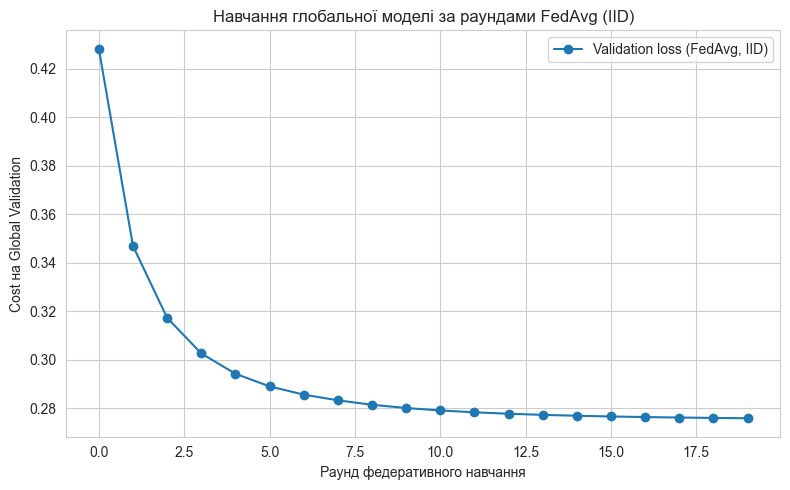

FedAvg (IID) — Global Test:
  accuracy: 0.9177
  macro_f1: 0.9305
  balanced_accuracy: 0.9288
  log_loss: 0.2396


In [17]:
def fedavg_aggregate(client_params, client_sizes):
    """Агрегація FedAvg: зважене середнє параметрів за кількістю прикладів клієнта."""
    total = sum(client_sizes)
    W_agg = sum((n / total) * W for (W, b), n in zip(client_params, client_sizes))
    b_agg = sum((n / total) * b for (W, b), n in zip(client_params, client_sizes))
    return W_agg, b_agg


def federated_train(clients, d, C, rounds=20, local_epochs=1, lr=0.5, batch_size=32,
                     l2=0.001, seed=0, X_val=None, Y_val=None):
    """Повна симуляція FedAvg. Цикли по раундах/клієнтах дозволені методичкою."""
    global_model = SoftmaxRegression(d, C, l2=l2, seed=seed)
    val_loss_history, val_acc_history = [], []

    for rnd in range(rounds):
        Wg, bg = global_model.get_params()
        client_params, client_sizes = [], []

        for k, (Xk, yk) in enumerate(clients):
            Yk = one_hot(yk, C)
            local_model = SoftmaxRegression(d, C, l2=l2, seed=seed + rnd * 1000 + k)
            local_model.set_params(Wg, bg)  # старт з глобальної моделі
            train_minibatch(local_model, Xk, Yk, lr=lr, epochs=local_epochs,
                             batch_size=batch_size, seed=seed + k)
            client_params.append(local_model.get_params())
            client_sizes.append(len(yk))

        Wg, bg = fedavg_aggregate(client_params, client_sizes)
        global_model.set_params(Wg, bg)

        if X_val is not None:
            val_loss_history.append(global_model.loss(X_val, Y_val))
            val_acc_history.append(accuracy_score(np.argmax(Y_val, axis=1), global_model.predict(X_val)))

    return global_model, {'val_loss': val_loss_history, 'val_acc': val_acc_history}


# Базовий запуск FedAvg на IID-розподілі
fl_model_iid, fl_hist_iid = federated_train(
    clients_iid, X_pool_s.shape[1], C, rounds=20, local_epochs=1,
    lr=FINAL_LR, batch_size=32, l2=FINAL_L2, X_val=X_val_s, Y_val=Y_val
)

plt.figure(figsize=(8, 5))
plt.plot(fl_hist_iid['val_loss'], marker='o', label='Validation loss (FedAvg, IID)')
plt.xlabel('Раунд федеративного навчання')
plt.ylabel('Cost на Global Validation')
plt.title('Навчання глобальної моделі за раундами FedAvg (IID)')
plt.legend()
plt.tight_layout()
plt.show()

print("FedAvg (IID) — Global Test:")
for k, v in eval_metrics(fl_model_iid, X_test_s, y_test, Y_test).items():
    print(f"  {k}: {v:.4f}")


**Висновок:** Cost на Global Validation монотонно спадає з кожним раундом FedAvg і виходить на плато — глобальна модель успішно навчається без прямого доступу сервера до сирих даних клієнтів. Якість на Global Test (accuracy ≈ 0.92) виявляється **практично ідентичною** до централізованої моделі з Етапу 3 — це очікувано: при IID-розподілі кожен клієнт бачить репрезентативний зріз даних, тому усереднення локальних оновлень математично наближається до навчання на всіх даних одразу.

## Етап 6. Дослідження ефектів федеративного навчання

Порівняємо три типи моделей на **Global Test**:
1. **Локальні клієнтські моделі** — навчені лише на даних одного клієнта (Non-IID розподіл, α=0.3).
2. **Глобальна федеративна модель** — результат FedAvg на тому ж Non-IID розподілі.
3. **Централізована модель** — з Етапу 3 (навчена на всьому FL Train Pool одразу).

In [18]:
# Локальні моделі (кожен клієнт навчає модель лише на своїх даних, Non-IID)
local_results = []
for k, (Xk, yk) in enumerate(clients_niid_03):
    Yk = one_hot(yk, C)
    local_model = SoftmaxRegression(X_pool_s.shape[1], C, l2=FINAL_L2, seed=k)
    train_minibatch(local_model, Xk, Yk, lr=FINAL_LR, epochs=100, batch_size=32, seed=k)
    m = eval_metrics(local_model, X_test_s, y_test, Y_test)
    m['model'] = f'Local client {k} (n={len(yk)})'
    local_results.append(m)

# Глобальна федеративна модель на Non-IID
fl_model_niid, _ = federated_train(
    clients_niid_03, X_pool_s.shape[1], C, rounds=20, local_epochs=1,
    lr=FINAL_LR, batch_size=32, l2=FINAL_L2, X_val=X_val_s, Y_val=Y_val
)
fl_metrics = eval_metrics(fl_model_niid, X_test_s, y_test, Y_test)
fl_metrics['model'] = 'Global federated (Non-IID, alpha=0.3)'

central_metrics_row = dict(central_test_metrics)
central_metrics_row['model'] = 'Centralized (full FL Train Pool)'

comparison_df = pd.DataFrame(local_results + [fl_metrics, central_metrics_row])
comparison_df = comparison_df[['model', 'accuracy', 'macro_f1', 'balanced_accuracy', 'log_loss']]
display(comparison_df.round(4))


,model,accuracy,macro_f1,balanced_accuracy,log_loss
0,Local client 0 (n=446),0.5313,0.4336,0.5649,2.4301
1,Local client 1 (n=3444),0.7018,0.6733,0.7349,1.3246
2,Local client 2 (n=1417),0.6895,0.6379,0.6744,1.7155
3,Local client 3 (n=803),0.6758,0.7193,0.7757,2.9494
4,Local client 4 (n=3417),0.8570,0.8599,0.8531,0.3892
5,"Global federated (Non-IID, alpha=0.3)",0.8864,0.8982,0.8972,0.3040
6,Centralized (full FL Train Pool),0.9182,0.9308,0.9287,0.2339


**Висновок по таблиці порівняння:** локальні клієнтські моделі показують значно **нижчу** якість на Global Test (accuracy від ~0.53 до ~0.85, залежно від клієнта) порівняно з глобальною федеративною моделлю (~0.89) і централізованою (~0.92). Це логічно: кожна локальна модель "спеціалізується" лише на тих класах, які бачив саме її клієнт (через Non-IID розподіл), і тому погано узагальнюється на повний тестовий набір з усіма 7 класами. Глобальна федеративна модель, навпаки, об'єднує знання з усіх клієнтів через агрегацію ваг і показує якість, близьку до (хоч і трохи нижчу за) централізовану модель — це і є головна практична цінність федеративного навчання: **отримати модель, близьку за якістю до централізованої, без збору сирих даних в одному місці.**

### Експеримент 1. Вплив неоднорідності даних (параметр α)

,alpha,accuracy,macro_f1,balanced_accuracy,log_loss
0,5.0,0.9192,0.9328,0.9315,0.2411
1,1.0,0.9163,0.9308,0.9303,0.2464
2,0.3,0.8864,0.8982,0.8972,0.3040


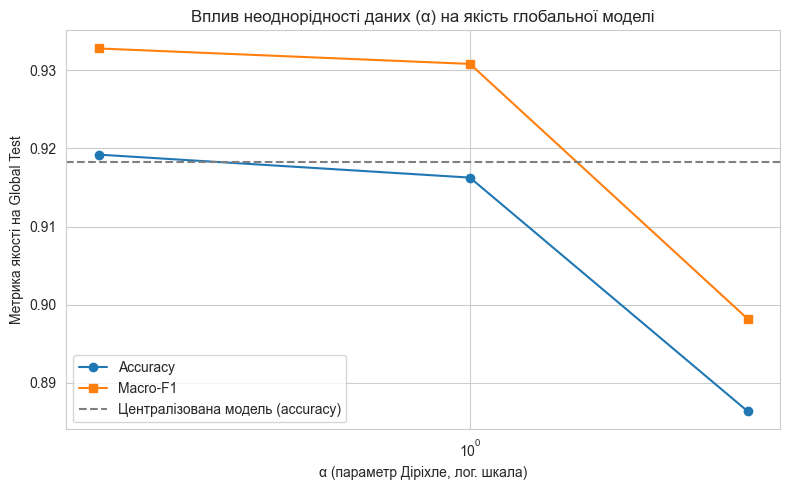

In [19]:
alphas = [5, 1, 0.3]
exp1_rows = []
exp1_models = {}

for a in alphas:
    clients_a = split_dirichlet(X_pool_s, y_pool, K, alpha=a, C=C, seed=42)
    model_a, hist_a = federated_train(
        clients_a, X_pool_s.shape[1], C, rounds=20, local_epochs=1,
        lr=FINAL_LR, batch_size=32, l2=FINAL_L2, X_val=X_val_s, Y_val=Y_val
    )
    metrics_a = eval_metrics(model_a, X_test_s, y_test, Y_test)
    metrics_a['alpha'] = a
    exp1_rows.append(metrics_a)
    exp1_models[a] = (model_a, hist_a)

exp1_df = pd.DataFrame(exp1_rows)[['alpha', 'accuracy', 'macro_f1', 'balanced_accuracy', 'log_loss']]
display(exp1_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(exp1_df['alpha'], exp1_df['accuracy'], marker='o', label='Accuracy')
plt.plot(exp1_df['alpha'], exp1_df['macro_f1'], marker='s', label='Macro-F1')
plt.axhline(central_test_metrics['accuracy'], color='gray', linestyle='--', label='Централізована модель (accuracy)')
plt.xscale('log')
plt.xlabel('α (параметр Діріхле, лог. шкала)')
plt.ylabel('Метрика якості на Global Test')
plt.title('Вплив неоднорідності даних (α) на якість глобальної моделі')
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


**Висновок з Експерименту 1:**
- Що **менше α** (сильніша неоднорідність), то **гірша** якість глобальної моделі: accuracy падає з ~0.92 при α=5 (майже IID) до ~0.89 при α=0.3 (сильний Non-IID).
- **Чому Non-IID погіршує федеративне навчання:** кожен клієнт локально оптимізує модель під *свій* локальний, перекошений розподіл класів. Коли клієнти дуже різні (малий α), їхні локальні градієнтні кроки "тягнуть" ваги в різних, іноді протилежних напрямках. Просте усереднення таких розбіжних оновлень (`FedAvg`) дає компроміс, який може бути гіршим за будь-яке локальне рішення для конкретного клієнта, і гіршим за глобальний оптимум, який побачила б централізована модель.
- **Чи може глобальна модель бути гіршою за централізовану?** Так, і це видно на графіку — за будь-якого α < ∞ (тобто за наявності хоч якоїсь неоднорідності) глобальна федеративна модель трохи поступається централізованій, оскільки централізована модель бачить **весь** датасет одночасно в кожному кроці навчання, тоді як федеративна — лише через "непрямі", усереднені оновлення.
- **Чи може глобальна модель бути гіршою за деякі локальні моделі?** Так, у принципі можливо — якщо локальний клієнт має дуже специфічний, вузький розподіл класів і ми оцінюємо якість **саме на цьому вузькому розподілі** (а не на Global Test), локальна модель клієнта може перевершити глобальну (яка змушена "балансувати" між усіма класами). Але на репрезентативному Global Test (як у нашій таблиці Етапу 6) глобальна модель майже завжди перевершує окремі локальні моделі, бо ті не бачили більшості класів взагалі.

### Експеримент 2. Вплив кількості локальних епох (E)

,E,accuracy,macro_f1,balanced_accuracy,log_loss
0,1,0.8864,0.8982,0.8972,0.3040
1,5,0.8751,0.8830,0.8825,0.3353
2,10,0.8653,0.8692,0.8699,0.3567


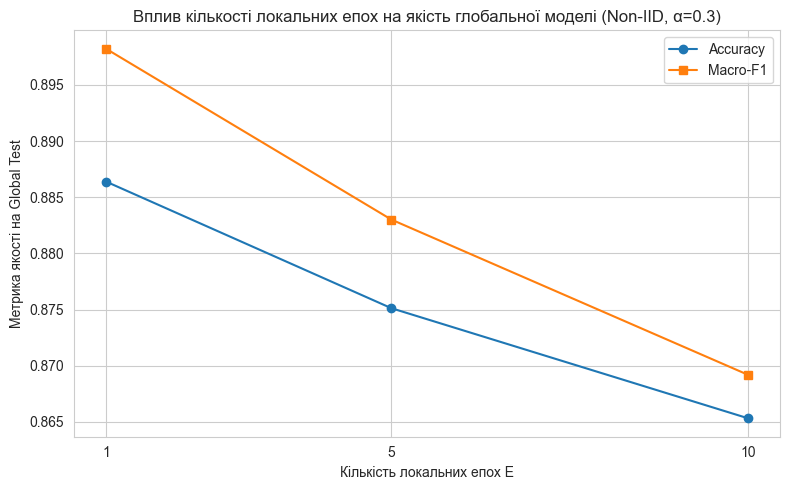

In [20]:
Es = [1, 5, 10]
exp2_rows = []

# Використовуємо Non-IID розподіл (alpha=0.3), щоб ефект client drift був явно видимий
for E in Es:
    model_e, hist_e = federated_train(
        clients_niid_03, X_pool_s.shape[1], C, rounds=20, local_epochs=E,
        lr=FINAL_LR, batch_size=32, l2=FINAL_L2, X_val=X_val_s, Y_val=Y_val
    )
    metrics_e = eval_metrics(model_e, X_test_s, y_test, Y_test)
    metrics_e['E'] = E
    exp2_rows.append(metrics_e)

exp2_df = pd.DataFrame(exp2_rows)[['E', 'accuracy', 'macro_f1', 'balanced_accuracy', 'log_loss']]
display(exp2_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(exp2_df['E'], exp2_df['accuracy'], marker='o', label='Accuracy')
plt.plot(exp2_df['E'], exp2_df['macro_f1'], marker='s', label='Macro-F1')
plt.xlabel('Кількість локальних епох E')
plt.ylabel('Метрика якості на Global Test')
plt.title('Вплив кількості локальних епох на якість глобальної моделі (Non-IID, α=0.3)')
plt.legend()
plt.xticks(Es)
plt.tight_layout()
plt.show()


**Висновок з Експерименту 2:**
- Якість глобальної моделі **падає** зі збільшенням кількості локальних епох: accuracy знижується з ~0.886 (E=1) до ~0.875 (E=5) і до ~0.865 (E=10).
- **Що таке client drift:** коли клієнт робить багато локальних кроків навчання (велике E), починаючи з глобальної моделі $w^t$, його локальна модель встигає "втекти" далеко від початкової точки у бік **власного** локального оптимуму (який, через Non-IID розподіл, відрізняється від глобального оптимуму). Це і називається client drift — локальна модель клієнта "дрейфує" від напрямку, який був би оптимальним для всіх даних разом.
- **Чому це погіршує глобальну модель у Non-IID сценарії:** коли сервер потім усереднює параметри клієнтів, які "розбіглись" у різних напрямках (кожен у бік свого локального оптимуму), результат усереднення може виявитись гіршим компромісом, ніж якби клієнти зробили лише кілька обережних кроків (E=1) і залишились ближче до спільної глобальної точки. У IID-сценарії цей ефект набагато слабший, бо локальні оптимуми всіх клієнтів і так близькі до глобального — дрейфувати "нікуди".

## Етап 7. Додатковий експеримент (опційний)

### Експеримент А. Вплив кількості клієнтів K

Порівняємо якість глобальної моделі при K=3, K=5, K=10 клієнтів (IID-розподіл, щоб ізолювати саме ефект кількості клієнтів від ефекту неоднорідності даних).

,K,n_per_client_avg,accuracy,macro_f1,balanced_accuracy,log_loss
0,3,3175,0.9182,0.9312,0.9301,0.2361
1,5,1905,0.9177,0.9305,0.9288,0.2396
2,10,952,0.9163,0.9288,0.9271,0.2513


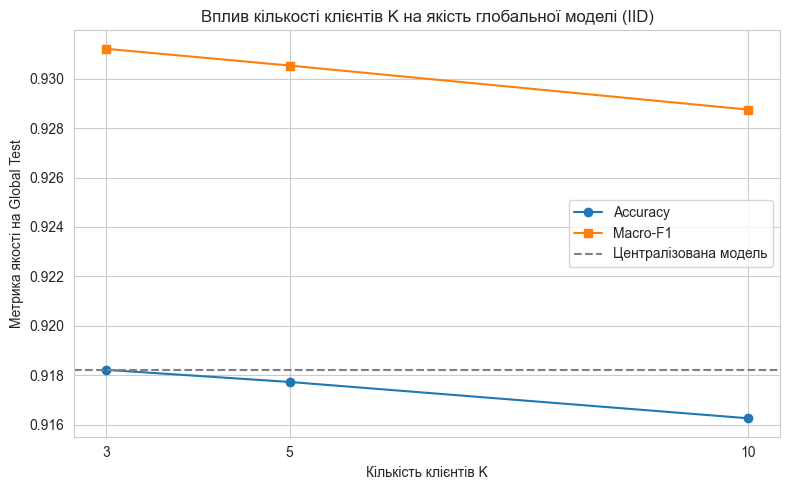

In [21]:
Ks = [3, 5, 10]
expA_rows = []

for k_ in Ks:
    clients_k = split_iid(X_pool_s, y_pool, k_)
    model_k, hist_k = federated_train(
        clients_k, X_pool_s.shape[1], C, rounds=20, local_epochs=1,
        lr=FINAL_LR, batch_size=32, l2=FINAL_L2, X_val=X_val_s, Y_val=Y_val
    )
    metrics_k = eval_metrics(model_k, X_test_s, y_test, Y_test)
    metrics_k['K'] = k_
    metrics_k['n_per_client_avg'] = len(y_pool) // k_
    expA_rows.append(metrics_k)

expA_df = pd.DataFrame(expA_rows)[['K', 'n_per_client_avg', 'accuracy', 'macro_f1', 'balanced_accuracy', 'log_loss']]
display(expA_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(expA_df['K'], expA_df['accuracy'], marker='o', label='Accuracy')
plt.plot(expA_df['K'], expA_df['macro_f1'], marker='s', label='Macro-F1')
plt.axhline(central_test_metrics['accuracy'], color='gray', linestyle='--', label='Централізована модель')
plt.xlabel('Кількість клієнтів K')
plt.ylabel('Метрика якості на Global Test')
plt.title('Вплив кількості клієнтів K на якість глобальної моделі (IID)')
plt.legend()
plt.xticks(Ks)
plt.tight_layout()
plt.show()


**Висновок з Експерименту А:** при IID-розподілі якість глобальної моделі залишається практично стабільною і близькою до централізованої моделі незалежно від K (accuracy знижується дуже незначно — з ~0.918 при K=3 до ~0.916 при K=10). Це логічно: за умови IID кожен клієнт, навіть маючи менше даних при більшому K, все одно бачить репрезентативний зріз усіх класів, тому його локальні градієнтні кроки узгоджені з глобальним напрямком. Невелике зниження якості при більшому K пояснюється тим, що кожен окремий клієнт має менше прикладів (наприклад, ~950 замість ~3175 при K=3), тому його локальна оцінка градієнта трохи шумніша — але агрегація FedAvg це значною мірою компенсує через усереднення. На відміну від Non-IID сценарію (Експеримент 1), тут збільшення кількості клієнтів **не є** головним чинником деградації якості — головним чинником є саме розподіл класів між клієнтами, а не їх кількість.

## Теоретичні питання

**1. Чому для багатокласової класифікації використовують softmax?**
Softmax перетворює довільні дійсні числа (логіти $Z$) у коректний розподіл ймовірностей: усі значення невід'ємні і в сумі дають 1 для кожного прикладу. Це дозволяє інтерпретувати вихід моделі як "ймовірність належності до кожного з $C$ класів" і природно узагальнює логістичну регресію (яка для 2 класів використовує сигмоїду — окремий випадок softmax при C=2) на довільну кількість класів.

**2. Чому крос-ентропія є природною функцією втрат для логістичної регресії?**
Крос-ентропія напряму випливає з принципу максимальної правдоподібності (Maximum Likelihood Estimation) для моделі, яка передбачає розподіл ймовірностей категоріальної величини: мінімізація крос-ентропії еквівалентна максимізації ймовірності того, що модель присвоїть правильному класу високу ймовірність. Вона також дає "зручний" (опуклий за параметрами при відсутності регуляризації) та чисельно стабільний градієнт $P - Y$, на відміну, наприклад, від MSE, який для softmax-виходу дає значно слабший і повільніший сигнал градієнта.

**3. Чим відрізняється Ridge-регуляризація від Lasso-регуляризації?**
Ridge (L2) штрафує суму **квадратів** ваг ($\|W\|_2^2$) — це "стискає" всі ваги до малих значень, але рідко робить їх точно нулями; добре працює при мультиколінеарності, розподіляючи вплив між корельованими ознаками. Lasso (L1) штрафує суму **модулів** ваг ($\|W\|_1$) — це має властивість робити частину ваг точно рівними нулю, тобто Lasso одночасно виконує неявний **відбір ознак**, тоді як Ridge лише зменшує їхній вплив, не прибираючи повністю.

**4. Чому параметр зміщення b зазвичай не регуляризують?**
Зсув $b$ не пов'язаний з жодною конкретною ознакою — він лише задає базовий рівень (пріорну ймовірність/логіт) кожного класу незалежно від вхідних даних. Регуляризація потрібна для запобігання надмірної чутливості моделі до окремих ознак (що й контролюють ваги $W$); штрафування $b$ не покращує узагальнення, а лише ускладнює підбір коректного базового рівня, особливо при незбалансованих класах.

**5. Що таке Data Leakage?**
Витік даних — ситуація, коли інформація з вибірки, призначеної для оцінки моделі (валідація/тест), тим чи іншим шляхом впливає на процес навчання або підготовки даних (наприклад, статистики масштабування чи відбір ознак пораховані на всьому датасеті, а не лише на Train). Наслідок — завищена, нерепрезентативна оцінка якості моделі, яка не підтверджується на справді нових даних.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**
Якщо підбирати гіперпараметри (learning rate, λ, розмір батчу тощо), орієнтуючись на результат на тесті, тест фактично перестає бути "незалежним" — він неявно стає частиною процесу навчання (ми обираємо ту конфігурацію, яка випадково найкраще підійшла саме під цей тест). Це завищує оцінку якості й унеможливлює чесну фінальну перевірку. Тому для підбору гіперпараметрів існує окрема Validation-вибірка, а Test використовується рівно один раз — в кінці, для фінальної незалежної оцінки.

**7. Чому параметри масштабування потрібно навчати лише на тренувальних даних?**
Із тих самих причин, що й вище (Data Leakage): якщо середнє/дисперсію порахувати із включенням Val/Test, модель опосередковано "підгляне" статистичні властивості даних, які мала б вперше побачити лише під час оцінки. Параметри масштабування — обчислені й "заморожені" виключно на Train — потім застосовуються (не перераховуються!) до Val і Test.

**8. Що таке федеративне навчання і які його основні переваги?**
Федеративне навчання (Federated Learning) — підхід до машинного навчання, коли модель навчається розподілено на пристроях/серверах клієнтів, які зберігають свої дані локально, а на центральний сервер передаються лише параметри (ваги) моделі, а не самі дані. Переваги: (1) **приватність** — сирі, потенційно чутливі дані ніколи не покидають пристрій клієнта; (2) економія на передачі великих обсягів сирих даних (передаються лише набагато менші вектори ваг); (3) можливість використовувати дані, які з юридичних чи технічних причин неможливо централізувати.

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**
Це порушує саму мету федеративного навчання — збереження приватності. Якщо сервер отримує сирі дані, це фактично зводить систему до звичайного централізованого навчання й усуває головну перевагу підходу: дані з різних джерел (наприклад, персональні, медичні, комерційно чутливі) можуть залишатись у власника, а не консолідуватись у єдиному, потенційно вразливому сховищі.

**10. Чому агрегація FedAvg використовує зважування за кількістю прикладів?**
Клієнт з більшою кількістю прикладів дає статистично надійніші (менш шумні) оцінки градієнта, тому логічно, щоб його оновлення мало пропорційно більший вплив на глобальну модель. Крім того, зважене середнє математично еквівалентне сумарному ефекту навчання на всіх прикладах одразу (як у Batch GD на об'єднаних даних), що зберігає узгодженість з поведінкою централізованого навчання при IID-даних.

**11. Що станеться, якщо агрегувати параметри клієнтів без зважування?**
Клієнти з дуже малою кількістю (і, як наслідок, дуже шумних, статистично ненадійних) прикладів матимуть такий самий вплив на глобальну модель, як клієнти з тисячами прикладів. Це спотворює фінальну модель у бік ненадійних, можливо нерепрезентативних локальних оновлень, особливо коли розміри клієнтів сильно відрізняються — саме такий сценарій ми спостерігали у Non-IID розподілі на Етапі 4.

**12. Що таке Non-IID дані?**
Non-IID (Not Independent and Identically Distributed) — ситуація, коли дані різних клієнтів мають різний статистичний розподіл (наприклад, різні пропорції класів, різні діапазони значень ознак), на відміну від IID, де кожен клієнт отримує приблизно репрезентативний, "однаково розподілений" зріз загальних даних.

**13. Чому федеративне навчання може погіршуватися на Non-IID даних?**
Тому що локальні градієнтні кроки кожного клієнта оптимізують модель під *його* локальний (перекошений) розподіл, а не під глобальний. Коли клієнти суттєво відрізняються один від одного, їхні локальні оновлення "тягнуть" параметри в різних, іноді протилежних напрямках, і просте усереднення (FedAvg) таких розбіжних оновлень дає гірший компроміс, ніж пряме навчання на об'єднаних даних — це підтверджено емпірично в Експерименті 1 (Етап 6).

**14. Що таке клієнтський дрейф (client drift)?**
Це явище, коли локальна модель клієнта, навчаючись протягом кількох (особливо багатьох) локальних епох, починаючи з глобальної точки $w^t$, "відходить" усе далі в бік свого власного локального оптимуму — оптимального лише для даних цього конкретного клієнта, який через Non-IID розподіл відрізняється від глобального оптимуму.

**15. Як кількість локальних епох впливає на глобальну модель?**
У Non-IID сценарії більша кількість локальних епох посилює клієнтський дрейф: клієнти "розбігаються" далі один від одного перед агрегацією, тому усереднене оновлення виявляється гіршим компромісом — це підтвердив Експеримент 2 (Етап 6), де якість глобальної моделі монотонно падала при зростанні E з 1 до 10. У IID-сценарії цей ефект набагато слабший, оскільки локальні оптимуми клієнтів і так близькі до глобального.

**16. Чи може глобальна модель бути гіршою за централізовану модель? Чому?**
Так, і особливо за умов Non-IID-розподілу (це підтверджено в Експерименті 1). Централізована модель на кожному кроці навчання "бачить" весь датасет одразу і напряму оптимізує єдину глобальну функцію втрат. Федеративна модель натомість отримує лише **непрямі**, усереднені оновлення від клієнтів, кожен з яких оптимізував свою локальну (можливо, зміщену) версію задачі — тому теоретична верхня межа якості федеративної моделі при неоднорідних даних, як правило, нижча за централізовану.

**17. Які метрики краще використовувати для багатокласової класифікації з можливим дисбалансом класів?**
Просту **accuracy** використовувати недостатньо, оскільки вона може бути оманливо високою, якщо модель добре розпізнає лише домінантні класи, ігноруючи рідкісні. Кращий вибір: **macro-F1** (усереднює F1-міру по класах з однаковою вагою кожного класу, незалежно від його розміру), **balanced accuracy** (середнє з recall по кожному класу) та **log-loss** (враховує впевненість/каліброваність прогнозів, а не лише фінальний вибір класу). Саме тому в цій роботі використано весь набір цих чотирьох метрик разом, а не лише accuracy.

## Загальний висновок

У цій роботі реалізовано багатокласову логістичну регресію (softmax) "з нуля" на numpy — включно з векторизованим обчисленням softmax, крос-ентропійної функції втрат з L2-регуляризацією та її градієнтів (коректність підтверджена через gradient checking з похибкою порядку $10^{-8}$). Центральна модель, навчена на всьому FL Train Pool, досягла accuracy ≈ 0.92 та macro-F1 ≈ 0.93 на Global Test, слугуючи еталоном для порівняння.

Далі реалізовано повну симуляцію федеративного навчання (FedAvg): коректний розподіл даних між клієнтами (сервер ніколи не бачить сирих даних клієнтів), два типи розподілу (IID та Non-IID через Діріхле), зважена агрегація параметрів за кількістю прикладів клієнта. Ключові емпіричні результати:

1. При **IID**-розподілі глобальна федеративна модель майже не поступається централізованій — федеративне навчання "працює" без суттєвих втрат якості.
2. Зростання **неоднорідності даних** (менше α у розподілі Діріхле) послідовно погіршує якість глобальної моделі — від ~0.92 (α=5) до ~0.89 (α=0.3) accuracy.
3. Збільшення **кількості локальних епох** у Non-IID сценарії посилює клієнтський дрейф і теж погіршує глобальну модель (з ~0.886 при E=1 до ~0.865 при E=10) — це прямий компроміс між обчислювальною ефективністю (менше раундів комунікації за рахунок більшої локальної роботи) та якістю фінальної моделі.
4. Локальні клієнтські моделі, навчені ізольовано на своїх (перекошених) даних, значно поступаються і глобальній, і централізованій моделі на репрезентативному тестовому наборі — це демонструє головну практичну цінність федеративного навчання: об'єднання знань багатьох клієнтів без централізації самих даних.
5. Кількість клієнтів (K) сама по собі, за умови IID-розподілу, чинить значно менший вплив на якість, ніж однорідність розподілу класів між ними — головним фактором ризику у федеративних системах є саме Non-IID природа реальних розподілених даних, а не їх кількість джерел.